# Pinwheel datasets and gradient descent

Builds three three-class pinwheel datasets, $(a,b)=(-2,0.3)$, $(-2.5,1.1)$, $(-2.5,1.3)$, decides separability of each by a linear program, runs gradient descent on mean logistic loss from $W_0=0$ for $n=2\times10^5$ steps, and shades the regions of $W_n$.

Output: `pinwheel_gd.pdf`. The results are kept in the dictionary `runs`, keyed by $(a,b)$, for use by `pinwheel_percep.ipynb`. Running all cells takes about half a minute.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import linprog
from scipy.special import logsumexp, softmax
from time import perf_counter

## Pinwheel datasets

Each class is a blob of 88 points (48 on a wobbly boundary, 40 inside) along the segment from $(a,1)$ to $(b,1)$. The three classes are rotations of one blob by $0^\circ$, $120^\circ$, $240^\circ$. The random seed is fixed, so the datasets are reproducible.

In [15]:
RNG = np.random.default_rng(0)
NB, NI = 48, 40                                   # boundary and interior points per class
_T = np.linspace(0, 2*np.pi, NB, endpoint=False)
_U = RNG.uniform(size=(NI, 2))

def rot(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s], [s, c]])

def blobs(a, b, width=0.3, wobble=0.15):
    "Return the three classes as a list of (88, 2) arrays."
    cx, L = (a + b)/2, (b - a)/2
    r = 1 + wobble*(0.5*np.sin(3*_T) + 0.3*np.cos(5*_T + 1))
    bd = np.stack([cx + L*r*np.cos(_T), 1 + width*r*np.sin(_T)], 1)
    rr, th = np.sqrt(_U[:, 0])*0.9, 2*np.pi*_U[:, 1]
    rin = 1 + wobble*(0.5*np.sin(3*th) + 0.3*np.cos(5*th + 1))
    inn = np.stack([cx + L*rr*rin*np.cos(th), 1 + width*rr*rin*np.sin(th)], 1)
    base = np.vstack([bd, inn])
    return [base @ rot(2*np.pi*i/3).T for i in range(3)]

def lift(P):
    "Augment samples: x -> (x, 1)."
    return np.hstack([P, np.ones((len(P), 1))])

## Separability by linear programming

A centered weight $W$ is separating if $y_i\ge y_j$ for every sample in class $i$ and every $j$. These inequalities and the centering condition are linear in $W$.

- `strict=False`: asks for $W\ne0$ with $y_i-y_j\ge0$, using the linear normalization $\sum(y_i-y_j)=1$ (valid for full-rank datasets).
- `strict=True`: asks for $y_i-y_j\ge1$, that is, separation with a positive margin.

Each returns a $3\times3$ weight, or `None` if the program is infeasible.

In [16]:
def sep_lp(C, strict):
    rows = []
    for i in range(3):
        Z = lift(C[i])
        for j in range(3):
            if j != i:
                G = np.zeros((len(Z), 9))
                G[:, 3*i:3*i+3] += Z
                G[:, 3*j:3*j+3] -= Z
                rows.append(G)
    G = np.vstack(rows)                                  # each row gives y_i - y_j
    cen = [np.tile(np.eye(3)[k], 3) for k in range(3)]   # centering: w_1 + w_2 + w_3 = 0
    free = [(None, None)]*9
    if strict:
        res = linprog(np.zeros(9), A_ub=-G, b_ub=-np.ones(len(G)),
                      A_eq=np.vstack(cen), b_eq=np.zeros(3), bounds=free, method='highs')
    else:
        res = linprog(np.zeros(9), A_ub=-G, b_ub=np.zeros(len(G)),
                      A_eq=np.vstack([G.sum(0)] + cen), b_eq=[1, 0, 0, 0], bounds=free, method='highs')
    return res.x.reshape(3, 3) if res.status == 0 else None

def hulls_disjoint(A, B):
    "True if the convex hulls of A and B are strictly separated by a line."
    Z = np.vstack([lift(A), -lift(B)])
    res = linprog(np.zeros(3), A_ub=-Z, b_ub=-np.ones(len(Z)), bounds=[(None, None)]*3, method='highs')
    return res.status == 0

## Gradient descent on mean logistic loss

Starts from $W_0=0$ with step $1/L$, where $L$ is the mean of $|\tilde x_k|^2$. This bounds the second derivative of $J$, since $\operatorname{diag}(q)-q\otimes q\le I$. The norm $\|W_n\|$ and the loss are recorded at 300 log-spaced steps. The run also records the first step $n$ at which $W_n$ separates the data, meaning every sample's own level is strictly highest, together with that $W_n$; for a dataset that is not separable this never happens.

In [17]:
def gd(X, y, iters=200_000):
    Pm = np.eye(3)[y]                                    # one-hot targets
    N = len(X)
    t = 1/np.mean(np.sum(X**2, 1))
    W = np.zeros((3, 3))
    norms, losses = [], []
    rows = np.arange(N)
    W_sep, n_sep = None, None
    rec = set(np.unique(np.logspace(0, np.log10(iters), 300).astype(int)))
    for n in range(1, iters + 1):
        Q = softmax(X @ W.T, axis=1)
        W -= t*(Q - Pm).T @ X/N
        if n_sep is None:                                # first separation?
            Y = X @ W.T
            own = Y[rows, y].copy()
            Y[rows, y] = -np.inf
            if (own > Y.max(1)).all():
                W_sep, n_sep = W.copy(), n
        if n in rec:
            Y = X @ W.T
            norms.append((n, np.linalg.norm(W)))
            losses.append((n, np.mean(logsumexp(Y, axis=1) - np.sum(Pm*Y, 1))))
    return W, np.array(norms), np.array(losses), W_sep, n_sep

## Run the three datasets

This cell takes about half a minute.

In [18]:
PARAMS = [(-2, 0.3), (-2.5, 1.1), (-2.5, 1.3)]
runs = {}
for a, b in PARAMS:
    C = blobs(a, b)
    X = np.vstack([lift(P) for P in C])
    y = np.concatenate([[i]*len(P) for i, P in enumerate(C)])
    separable = sep_lp(C, strict=False) is not None
    strictly = sep_lp(C, strict=True) is not None
    disjoint = all(hulls_disjoint(C[i], C[j]) for i, j in [(0, 1), (0, 2), (1, 2)])
    t0 = perf_counter()
    W, norms, losses, W_sep, n_sep = gd(X, y)
    seconds = perf_counter() - t0
    grad = (softmax(X @ W.T, axis=1) - np.eye(3)[y]).T @ X/len(X)
    wrong = int((np.argmax(X @ W.T, 1) != y).sum())
    runs[(a, b)] = dict(C=C, X=X, y=y, W=W, norms=norms, losses=losses, seconds=seconds,
                        separable=separable, W_sep=W_sep, n_sep=n_sep)
    print(f"(a,b) = ({a}, {b}): separable = {separable}, strictly = {strictly}, "
          f"hulls pairwise disjoint = {disjoint}")
    print(f"   after {int(norms[-1, 0])} steps: |W| = {norms[-1, 1]:.2f}, loss = {losses[-1, 1]:.2e}, "
          f"|grad| = {np.linalg.norm(grad):.1e}, misclassified = {wrong} of {len(X)}, {seconds:.1f} s")
    print(f"   first separation: " + (f"n = {n_sep}" if n_sep else "never"))

(a,b) = (-2, 0.3): separable = True, strictly = True, hulls pairwise disjoint = True
   after 200000 steps: |W| = 17.61, loss = 7.28e-05, |grad| = 3.4e-05, misclassified = 0 of 264, 9.8 s
   first separation: n = 1
(a,b) = (-2.5, 1.1): separable = True, strictly = True, hulls pairwise disjoint = True
   after 200000 steps: |W| = 54.16, loss = 9.19e-03, |grad| = 3.3e-04, misclassified = 0 of 264, 9.9 s
   first separation: n = 6128
(a,b) = (-2.5, 1.3): separable = False, strictly = False, hulls pairwise disjoint = True
   after 200000 steps: |W| = 21.55, loss = 1.26e-01, |grad| = 7.7e-08, misclassified = 12 of 264, 14.7 s
   first separation: never


## Figure

Each panel shades the regions $R_i$ where level $i$ is highest under $W_n$. For a separable dataset, gradient descent is stopped at the first $n$ for which $W_n$ separates the data. For the dataset that is not separable this never happens, and $W_n$ at $n=2\times10^5$ approximates the minimizer. The plotting settings defined here are reused by `pinwheel_percep.ipynb`.

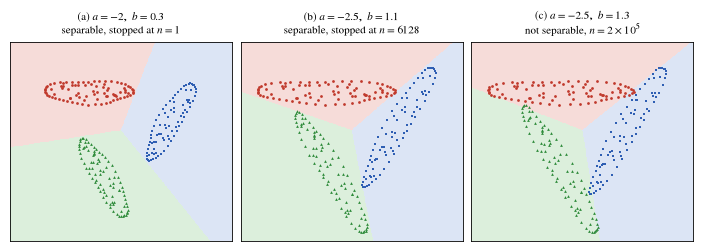

In [19]:
plt.rcParams.update({'font.family': 'serif',
                     'font.serif': ['TeX Gyre Termes', 'Times New Roman', 'Times', 'DejaVu Serif'],
                     'mathtext.fontset': 'stix', 'font.size': 8, 'axes.linewidth': 0.6})
cols = ['#c0392b', '#2e8b3a', '#2f5fb3']
marks = ['o', '^', 's']
tints = ListedColormap(['#f6dcd9', '#dcefdc', '#dce5f5'])
LIM = 2.9
g = np.linspace(-LIM, LIM, 500)
X1, X2 = np.meshgrid(g, g)
GRID = np.stack([X1.ravel(), X2.ravel(), np.ones(X1.size)], 1)

def regions(ax, C, W, title):
    "Shade the regions of W and plot the three classes."
    R = np.argmax(GRID @ W.T, 1).reshape(X1.shape)
    ax.imshow(R, extent=(-LIM, LIM, -LIM, LIM), origin='lower', cmap=tints, vmin=0, vmax=2,
              interpolation='nearest')
    for P, c, m in zip(C, cols, marks):
        ax.scatter(P[:, 0], P[:, 1], s=4, c=c, marker=m, linewidths=0)
    ax.set_xlim(-LIM, LIM); ax.set_ylim(-LIM, 2.3); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=8)

fig, axs = plt.subplots(1, 3, figsize=(6.9, 2.5))
for ax, (a, b), lab in zip(axs, PARAMS, 'abc'):
    r = runs[(a, b)]
    if r['n_sep'] is not None:
        W, sub = r['W_sep'], f"separable, stopped at $n={r['n_sep']}$"
    else:
        W, sub = r['W'], 'not separable, $n=2\\times10^5$'
    regions(ax, r['C'], W, f'({lab}) $a={a},\\ b={b}$\n{sub}')
plt.tight_layout(pad=0.3, w_pad=0.8)
plt.savefig('pinwheel_gd.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()